# 5. Clustering - Orbital Groups

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.5f}'.format)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

Load pandas, K-Means, the silhouette score and joblib; create output folders. Numbers are shown as normal values (like 3,810,113.98854) instead of scientific notation (3.810114e+06).

## Read the data

In [2]:
data = pd.read_csv('clustering.csv')
data.head()

,a,e,i,per,moid_ld,class,pha,neo
0,2.76917,0.07601,10.59407,"1,683.14570",620.64053,MBA,0,0
1,2.77384,0.22997,34.83293,"1,687.41099",480.34864,MBA,0,0
2,2.66829,0.25694,12.99104,"1,592.01377",402.51464,MBA,0,0
3,2.36142,0.08872,7.14177,"1,325.43276",443.45143,MBA,0,0
4,2.57404,0.19091,5.36743,"1,508.41442",426.43303,MBA,0,0


Read the clustering data made in notebook 2.

In [3]:
data.shape

(932336, 8)

Confirm the size of the data.

## Features used for clustering

In [4]:
features = ['a', 'e', 'i', 'per', 'moid_ld']
data[features].describe().T

,count,mean,std,min,25%,50%,75%,max
a,"932,336.00000",2.93262,36.45821,0.55542,2.38909,2.64797,3.00298,"33,488.89595"
e,"932,336.00000",0.15622,0.09300,0.00000,0.09216,0.14493,0.20059,0.99985
i,"932,336.00000",8.99669,6.60694,0.00774,4.13556,7.35785,12.33273,175.08290
per,"932,336.00000","5,181.15338","2,341,158.67891",151.19178,"1,348.79734","1,573.86807","1,900.76143","2,238,461,721.15179"
moid_ld,"932,336.00000",551.16312,841.65546,0.00018,381.46735,483.07088,620.22023,"30,929.90842"


Check the ranges of the 5 clustering features.

## Log transform for long-tail columns, then scale

In [5]:
X = data[features].copy()
X['a'] = np.log1p(X['a'])
X['per'] = np.log1p(X['per'])
X['moid_ld'] = np.log1p(X['moid_ld'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 0.10211227, -0.86249319,  0.24177208,  0.14031185,  0.46400409],
       [ 0.10822897,  0.79301427,  3.91047103,  0.14711012,  0.07808928],
       [-0.03172207,  1.08294968,  0.60456897, -0.00920614, -0.18803749],
       [-0.46269538, -0.72580128, -0.28075384, -0.50141401, -0.04224183],
       [-0.16012631,  0.37302877, -0.54931155, -0.15408825, -0.1011515 ]])

Log shrinks long tails and scaling puts all features on the same scale, because K-Means uses distances.

## Sample of 50,000 rows to choose k quickly

In [6]:
np.random.seed(42)
sample_index = np.random.choice(len(X_scaled), 50000, replace=False)
X_sample = X_scaled[sample_index]
X_sample.shape

(50000, 5)

A 50,000 sample makes testing many k values fast.

## Elbow method and silhouette score for k = 2 to 10

In [7]:
k_values = range(2, 11)
inertia = []
silhouette = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sample)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_sample, labels, sample_size=10000, random_state=42))
    print('k =', k, ' silhouette =', round(silhouette[-1], 4))

k = 2  silhouette = 0.8789


k = 3  silhouette = 0.7208


k = 4  silhouette = 0.2934


k = 5  silhouette = 0.3069


k = 6  silhouette = 0.3164


k = 7  silhouette = 0.2967


k = 8  silhouette = 0.2927


k = 9  silhouette = 0.2795


k = 10  silhouette = 0.3066


Compute inertia (elbow) and silhouette for k = 2 to 10 to choose the number of groups.

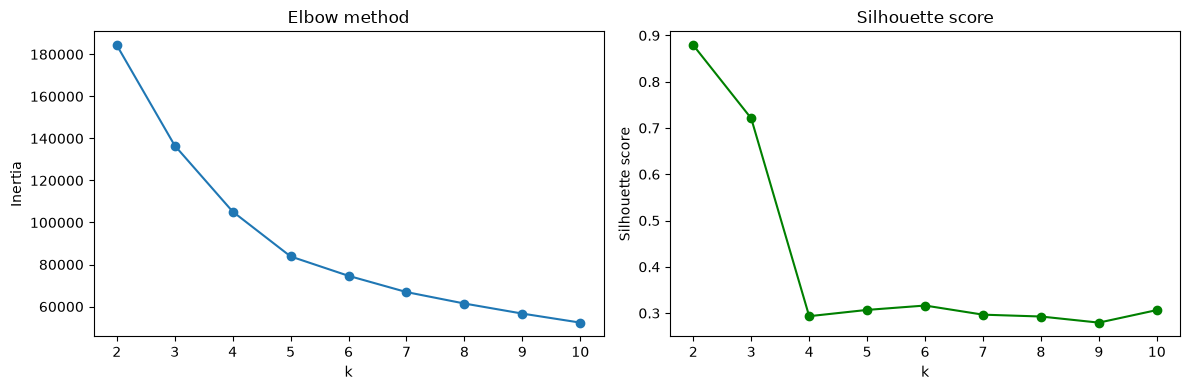

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow method')

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette, marker='o', color='green')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('Silhouette score')

plt.tight_layout()
plt.savefig('images/elbow_silhouette.png')
plt.show()

Plot both measures to see the elbow and the best silhouette.

## K-Means results table

In [9]:
kmeans_table = pd.DataFrame({'Model': 'K-Means', 'k': list(k_values), 'Inertia': inertia, 'Silhouette': silhouette}).round(4)
kmeans_table

,Model,k,Inertia,Silhouette
0,K-Means,2,"184,338.06210",0.87890
1,K-Means,3,"136,592.15400",0.72080
2,K-Means,4,"105,179.56940",0.29340
3,K-Means,5,"83,849.45550",0.30690
4,K-Means,6,"74,623.63030",0.31640
5,K-Means,7,"66,892.50070",0.29670
6,K-Means,8,"61,445.11760",0.29270
7,K-Means,9,"56,658.91840",0.27950
8,K-Means,10,"52,364.07970",0.30660


Keep the k results as a comparison table.

## Check what k = 2, 3, 4 separate (on the sample)

In [10]:
sample_class = data['class'].values[sample_index]

for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_sample)
    print('k =', k)
    print(pd.crosstab(sample_class, labels))
    print()

k = 2
col_0      0    1
row_0            
AMO      447    0
APO      661    0
AST        7    0
ATE       86    0
CEN        9   11
IEO        1    0
IMB     1064    0
MBA    44635    0
MCA      946    0
OMB     1507    0
TJN      419    0
TNO        0  207



k = 3
col_0      0    1    2
row_0                 
AMO       16    0  431
APO        0    0  661
AST        7    0    0
ATE        0    0   86
CEN        9   11    0
IEO        0    0    1
IMB     1064    0    0
MBA    44635    0    0
MCA      884    0   62
OMB     1506    0    1
TJN      419    0    0
TNO        0  207    0



k = 4
col_0      0    1    2      3
row_0                        
AMO       13    0  425      9
APO        0    0  661      0
AST        1    0    0      6
ATE        0    0   86      0
CEN        0   11    0      9
IEO        0    0    1      0
IMB       14    0    0   1050
MBA    27284    0    0  17351
MCA      471    0   40    435
OMB      290    0    1   1216
TJN        0    0    0    419
TNO        0  207    0      0



Check what k = 2, 3 and 4 separate, so k is chosen by meaning and not only by a number.

## Choose k = 3 (k = 2 only splits off far objects; k = 3 has the next best silhouette and 3 clear groups)

In [11]:
best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
data['cluster'] = kmeans.fit_predict(X_scaled)

final_sil = silhouette_score(X_scaled, data['cluster'], sample_size=20000, random_state=42)
print('Silhouette (full data, k =', best_k, '):', round(final_sil, 4))

Silhouette (full data, k = 3 ): 0.7148


Run K-Means with k = 3 on all asteroids and measure its silhouette.

## Cluster sizes

In [12]:
data['cluster'].value_counts().sort_index()

cluster
0     23871
1      3774
2    904691
Name: count, dtype: int64

See how many asteroids fall in each cluster.

## Give each cluster a name using its median a (AU)

In [13]:
median_a = data.groupby('cluster')['a'].median().sort_values()
names = ['Near-Earth group', 'Main belt group', 'Outer solar system group']
cluster_names = {}
for n in range(len(median_a)):
    cluster_names[median_a.index[n]] = names[n]

data['cluster_name'] = data['cluster'].map(cluster_names)
cluster_names

{np.int32(0): 'Near-Earth group',
 np.int32(2): 'Main belt group',
 np.int32(1): 'Outer solar system group'}

Give the clusters readable names based on their distance from the Sun.

## Average values of each cluster (original units)

In [14]:
cluster_profile = data.groupby('cluster')[features].median().round(3)
cluster_profile['count'] = data['cluster'].value_counts().sort_index()
cluster_profile['pha_%'] = (data.groupby('cluster')['pha'].apply(lambda x: (x == 'Y').mean() * 100)).round(2)
cluster_profile['neo_%'] = (data.groupby('cluster')['neo'].apply(lambda x: (x == 'Y').mean() * 100)).round(2)
cluster_profile

,a,e,i,per,moid_ld,count,pha_%,neo_%
cluster,,,,,,,,
0,1.76600,0.46000,8.92200,857.35900,22.44200,23871,0.00000,0.00000
1,43.76300,0.16300,10.67500,"105,745.98100","14,000.04000",3774,0.00000,0.00000
2,2.65500,0.14200,7.31600,"1,579.97800",488.33400,904691,0.00000,0.00000


Median values per cluster describe what each group looks like.

## Clusters vs existing class labels

In [15]:
ct = pd.crosstab(data['class'], data['cluster'], margins=True, margins_name='Total')
ct

cluster,0,1,2,Total
class,,,,
AMO,8207,4,237,8448
APO,12684,0,0,12684
AST,2,0,55,57
ATE,1729,0,0,1729
CEN,2,310,191,503
IEO,22,0,0,22
IMB,0,0,19702,19702
MBA,0,0,832650,832650
MCA,1165,0,16624,17789


Compare clusters with the expert classes to see if they match known populations.

## Clusters vs pha and neo

In [16]:
print(pd.crosstab(data['pha'], data['cluster'], margins=True, margins_name='Total'))
print()
print(pd.crosstab(data['neo'], data['cluster'], margins=True, margins_name='Total'))

cluster      0     1       2   Total
pha                                 
0        21805  3774  904691  930270
1         2066     0       0    2066
Total    23871  3774  904691  932336

cluster      0     1       2   Total
neo                                 
0         1229  3770  904454  909453
1        22642     4     237   22883
Total    23871  3774  904691  932336


Check where the PHAs and NEOs ended up.

## Plot clusters (a vs e, a vs i)

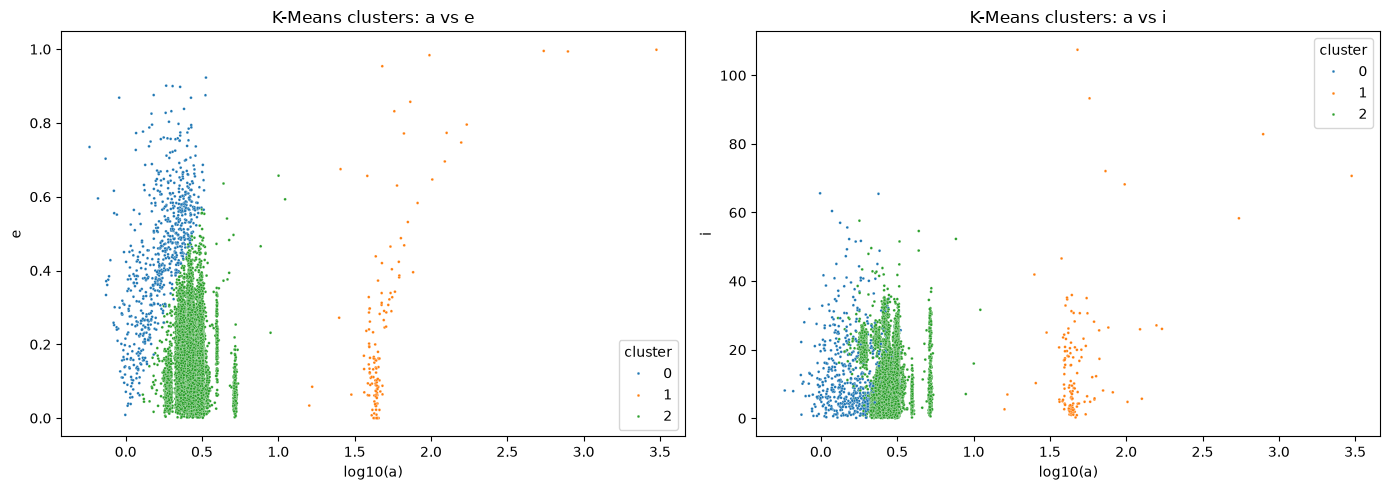

In [17]:
plot_df = data.sample(30000, random_state=42)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x=np.log10(plot_df['a']), y=plot_df['e'], hue=plot_df['cluster'], palette='tab10', s=4)
plt.xlabel('log10(a)')
plt.title('K-Means clusters: a vs e')

plt.subplot(1, 2, 2)
sns.scatterplot(x=np.log10(plot_df['a']), y=plot_df['i'], hue=plot_df['cluster'], palette='tab10', s=4)
plt.xlabel('log10(a)')
plt.title('K-Means clusters: a vs i')

plt.tight_layout()
plt.savefig('images/kmeans_clusters.png')
plt.show()

Plot the clusters to see the groups in orbit space.

## Save tables and models

In [18]:
kmeans_table.to_csv('results/kmeans_results.csv', index=False)
cluster_profile.to_csv('results/cluster_profile.csv')
pd.crosstab(data['class'], data['cluster']).to_csv('results/cluster_vs_class.csv')

joblib.dump(kmeans, 'models/kmeans_model.pkl')
joblib.dump(scaler, 'models/cluster_scaler.pkl')
joblib.dump(cluster_names, 'models/cluster_names.pkl')

plot_df[['a', 'e', 'i', 'cluster', 'cluster_name']].sample(5000, random_state=42).to_csv('models/cluster_sample.csv', index=False)
print('Saved')

Saved


Save tables, the model, the scaler, names and a small sample so the app can use them.